# LSRTM · pure-qP VTI / TTI

`AcousticVTILSRTM` and `AcousticTTILSRTM` are the Born (LSRTM) equations of the pure-qP
operators `AcousticVTI` / `AcousticTTI`: a background qP field `h1` driven by the source and a
scattered field `sh1` driven by the reflectivity $m_p = 2\,\delta v / v$ times the background
update. Each field takes the anisotropy term $S_n$ from the direction of its own wavefield
gradient, and the receivers record the scattered field. The derivation, the adjoint and what the
compiled backend supports are on the [Pure-qP VTI / TTI](../../user-guide/qp_born/) page.

This notebook images a model with a tilted anisotropic bed. The observed data are TTI Born data;
the background velocity is smoothed and $\varepsilon$, $\delta$ and the tilt $\theta$ are held
at their true values. The same data are then imaged with three operators -- isotropic
(`AcousticLSRTM`), VTI and TTI -- first as an RTM image (the gradient at $m_p = 0$), then by
least-squares RTM. Everything runs on `impl='c'` with boundary saving.

## 1. Model and survey

In [1]:
import sys, pathlib

_repo = pathlib.Path().resolve().parents[1]     # docs/notebooks/ -> repo root
if str(_repo / "src") not in sys.path:
    sys.path.insert(0, str(_repo / "src"))

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.path import Path
from scipy.ndimage import gaussian_filter, laplace

from sweep.equations import AcousticLSRTM, AcousticTTILSRTM, AcousticVTILSRTM
from sweep.propagator import BoundarySaving, PropTorch
from sweep.signal import ricker

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


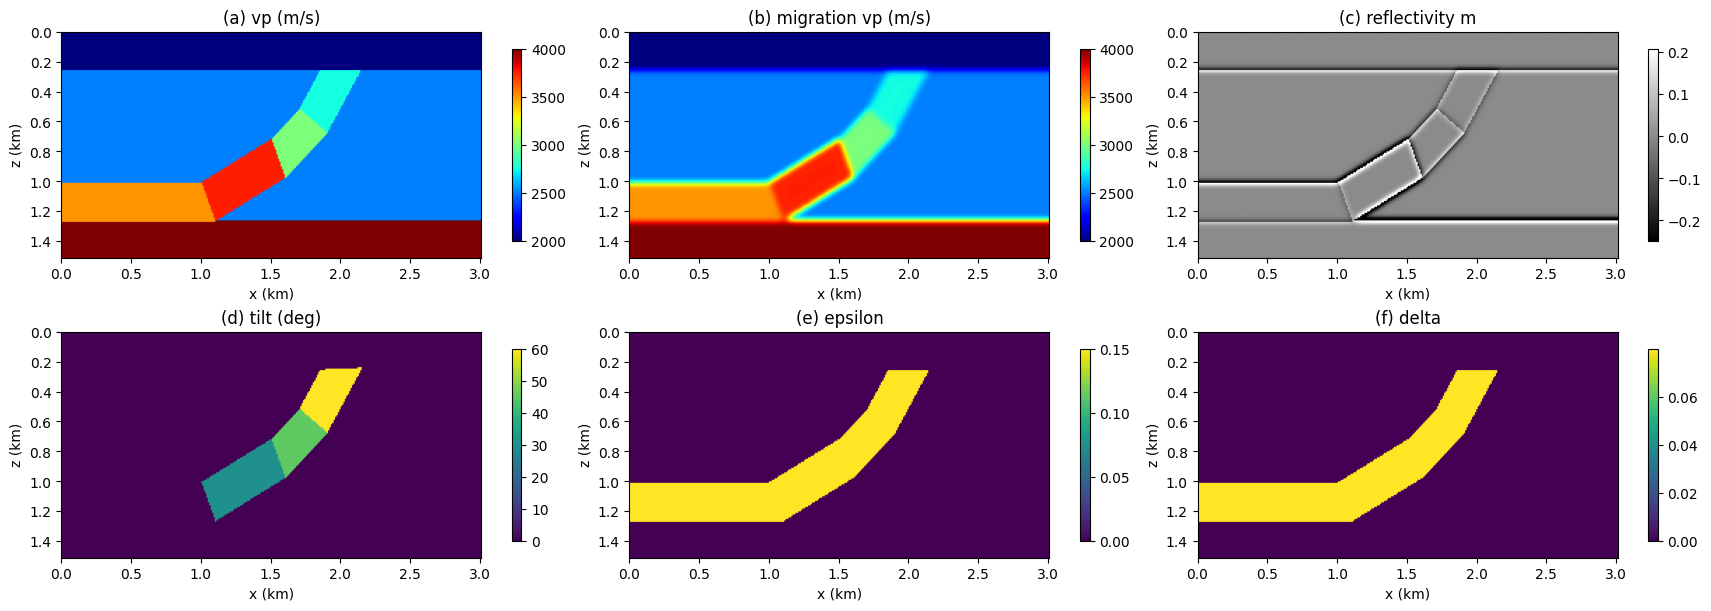

In [2]:
nz, nx, dh = 151, 301, 10.0                    # 1.5 km deep x 3 km, 10 m grid

def fill(a, corners, value):
    # set the cells inside the polygon `corners` ((x, z) grid points) to `value`
    zz, xx = np.mgrid[:nz, :nx]
    inside = Path(corners).contains_points(np.c_[xx.ravel(), zz.ravel()]).reshape(nz, nx)
    a[inside] = value

vp = np.zeros((nz, nx), np.float32)
tilt = np.zeros((nz, nx), np.float32)
fill(vp, [(-1, -1), (nx, -1), (nx, 25), (-1, 25)], 2000.0)
fill(vp, [(-1, 125), (nx, 125), (nx, nz), (-1, nz)], 4000.0)
fill(vp, [(-1, 100), (100, 100), (110, 126), (-1, 126)], 3500.0)    # the flat part of the bed
# the bed then bends up in three segments, tilted 30, 45 and 60 degrees
top, bottom = (100, 100), (110, 126)
for deg, x_top, x_bottom, v in ((30, 150, 160, 3750.0), (45, 170, 190, 3000.0), (60, 185, 215, 2750.0)):
    rise = np.tan(np.deg2rad(deg))
    top2 = (x_top, top[1] - rise * (x_top - top[0]))
    bottom2 = (x_bottom, bottom[1] - rise * (x_bottom - bottom[0]))
    fill(vp, [top, top2, bottom2, bottom], v)
    fill(tilt, [top, top2, bottom2, bottom], deg)
    top, bottom = top2, bottom2
vp[:26] = 2000.0
vp[vp == 0.0] = 2500.0

bed = np.isin(vp, (3500.0, 3750.0, 3000.0, 2750.0))      # the anisotropic bed
epsilon = np.where(bed, 0.15, 0.0).astype(np.float32)
delta = np.where(bed, 0.08, 0.0).astype(np.float32)
theta = np.deg2rad(tilt).astype(np.float32)              # the equations take radians

vp_s = gaussian_filter(vp, sigma=2).astype(np.float32)   # migration velocity
m_true = (2 * (vp - vp_s) / vp_s).astype(np.float32)     # reflectivity 2 dv / v

src_x = np.arange(0, nx, 4)                              # 76 shots every 40 m
nshots = len(src_x)
sources = np.stack([src_x, np.ones(nshots, np.int64)], 1)                  # (x, z), z = 10 m
rec_x = np.arange(0, nx, 2)                              # 151 receivers every 20 m
receivers = np.repeat(np.stack([rec_x, np.ones_like(rec_x)], 1)[None], nshots, 0)

dt, nt, fm, delay = 1e-3, 1601, 18.0, 0.1                # 1.6 s, 18 Hz Ricker
wavelet = ricker(np.arange(nt, dtype=np.float32) * dt - delay, f=fm)
order, abcn, batch = 8, 20, 4      # 8th order: ~4.5 points per shortest wavelength at 10 m

extent = [0, nx * dh / 1000, nz * dh / 1000, 0]
fig, ax = plt.subplots(2, 3, figsize=(17, 6), constrained_layout=True)
lo, hi = np.percentile(m_true, [1, 99])
panels = [(vp, "(a) vp (m/s)", dict(cmap="jet")),
          (vp_s, "(b) migration vp (m/s)", dict(cmap="jet", vmin=vp.min(), vmax=vp.max())),
          (m_true, "(c) reflectivity m", dict(cmap="gray", vmin=lo, vmax=hi)),
          (tilt, "(d) tilt (deg)", dict(cmap="viridis")),
          (epsilon, "(e) epsilon", dict(cmap="viridis")),
          (delta, "(f) delta", dict(cmap="viridis"))]
for a, (f, title, kw) in zip(ax.ravel(), panels):
    fig.colorbar(a.imshow(f, extent=extent, aspect="auto", **kw), ax=a, shrink=0.85)
    a.set_title(title); a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

## 2. Born data

The observed data are the TTI Born data of the true reflectivity on the smoothed background:
the scattered field `sh1`, recorded at every receiver, for all 76 shots. The shots run in
batches of four; boundary saving keeps the two fields on the whole CPML frame, so its memory
grows with the batch and with `abcn`.

observed data (shots, nt, receivers, 1): (76, 1601, 151, 1)


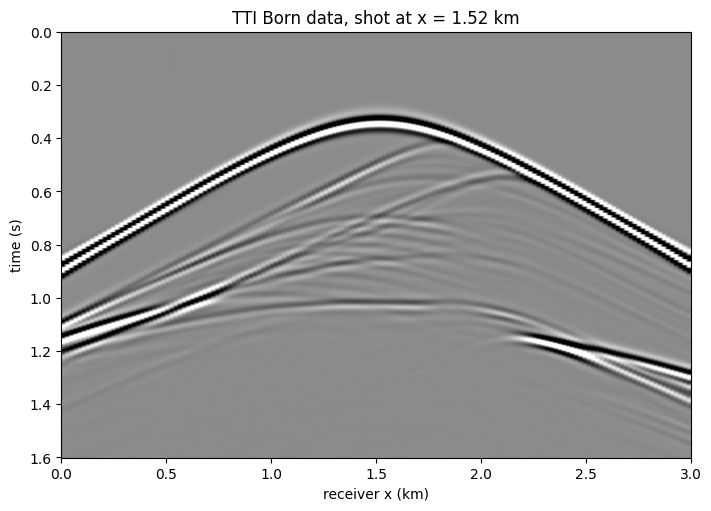

In [3]:
CASES = {"isotropic": AcousticLSRTM, "VTI": AcousticVTILSRTM, "TTI": AcousticTTILSRTM}
T = lambda a: torch.tensor(a, device=device)
background = {"isotropic": [T(vp_s)],
              "VTI": [T(vp_s), T(epsilon), T(delta)],
              "TTI": [T(vp_s), T(epsilon), T(delta), T(theta)]}

def solver(case):
    eq = CASES[case](spatial_order=order, device=device)
    return PropTorch(eq, shape=(nz, nx), dh=dh, dt=dt, nt=nt, dev=device, abcn=abcn,
                     impl="c", memory=BoundarySaving())

def born(case, mp):
    # the Born (scattered) data of reflectivity mp, every shot
    s, out = solver(case), []
    with torch.no_grad():
        for i in range(0, nshots, batch):
            out.append(s(wavelet, sources[i:i + batch], receivers[i:i + batch],
                         models=background[case] + [mp]))
    return torch.cat(out)

d_obs = born("TTI", T(m_true))
print("observed data (shots, nt, receivers, 1):", tuple(d_obs.shape))

shot = nshots // 2
g = d_obs[shot, :, :, 0].cpu().numpy()
lo, hi = np.percentile(g, [2, 98])
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.imshow(g, cmap="gray", vmin=lo, vmax=hi, aspect="auto",
          extent=[rec_x[0] * dh / 1000, rec_x[-1] * dh / 1000, nt * dt, 0])
ax.set_title(f"TTI Born data, shot at x = {src_x[shot] * dh / 1000:.2f} km")
ax.set_xlabel("receiver x (km)"); ax.set_ylabel("time (s)")
plt.show()

## 3. RTM: the gradient at $m_p = 0$

The negative gradient of $J = \tfrac12\lVert d(m_p) - d_{\rm obs}\rVert^2$ at $m_p = 0$ is the RTM
image of the residual -- here the data themselves. The top 20 rows (200 m) next to the sources and
receivers are left out of the gradient, and the plots show the image after a Laplacian filter,
which takes out the low-wavenumber backscatter RTM puts along strong contrasts.

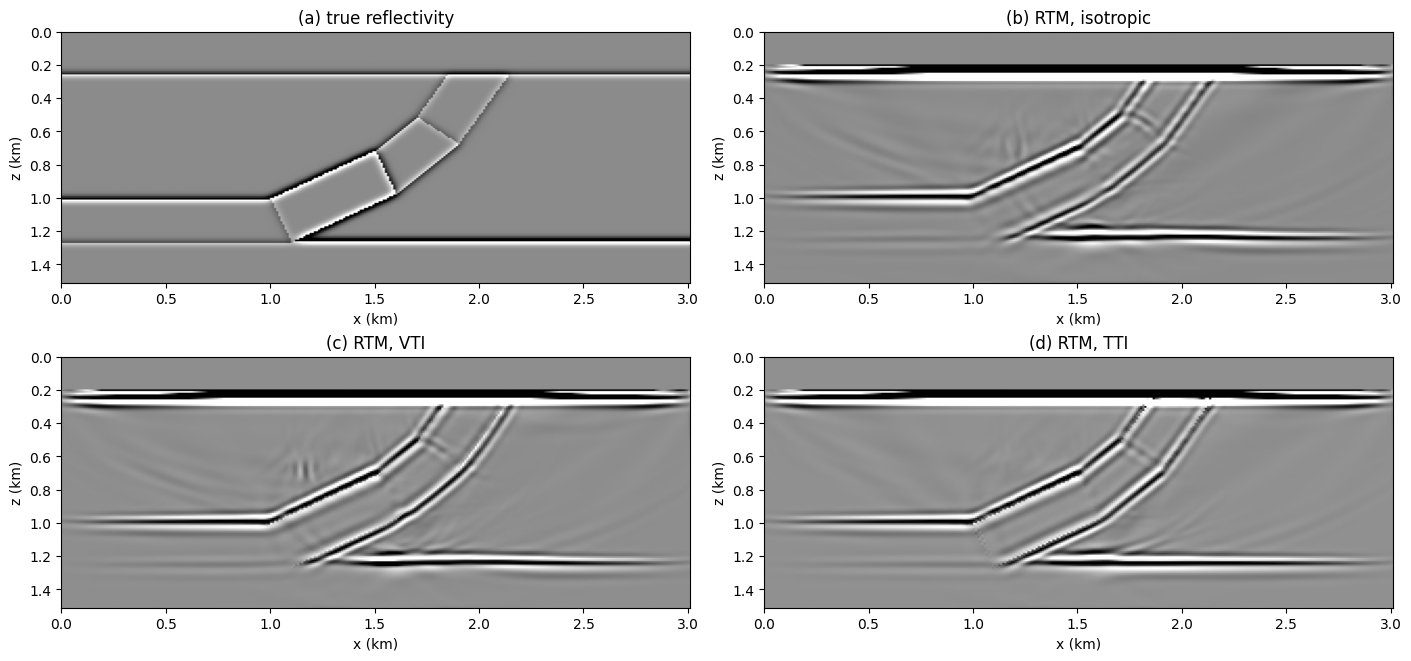

In [4]:
mask = torch.ones(nz, nx, device=device)
mask[:20] = 0

def misfit_grad(case, mp):
    # 0.5 |d(mp) - d_obs|^2 and its mp gradient, summed over the shots
    s, J, g = solver(case), 0.0, torch.zeros_like(mp)
    for i in range(0, nshots, batch):
        m = mp.detach().clone().requires_grad_(True)
        d = s(wavelet, sources[i:i + batch], receivers[i:i + batch], models=background[case] + [m])
        loss = 0.5 * (d - d_obs[i:i + batch]).pow(2).sum()
        loss.backward()
        J, g = J + loss.item(), g + m.grad
    return J, g * mask

rtm = {case: -misfit_grad(case, torch.zeros(nz, nx, device=device))[1].cpu().numpy() for case in CASES}

fig, ax = plt.subplots(2, 2, figsize=(14, 6.5), constrained_layout=True)
lo, hi = np.percentile(m_true, [1, 99])
ax[0, 0].imshow(m_true, cmap="gray", vmin=lo, vmax=hi, extent=extent, aspect="auto")
ax[0, 0].set_title("(a) true reflectivity")
for a, case, letter in zip(ax.ravel()[1:], CASES, "bcd"):
    img = -laplace(rtm[case])
    img[:20] = 0
    lo, hi = np.percentile(img[30:], [1, 99])
    a.imshow(img, cmap="gray", vmin=lo, vmax=hi, extent=extent, aspect="auto")
    a.set_title(f"({letter}) RTM, {case}")
for a in ax.ravel():
    a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

At this stage the three images differ little. The flat reflectors at 0.25, 1.0 and 1.25 km line
up in all three; along the tilted bed the differences are small shifts of its two sides and a few
extra arcs (VTI, near $x = 1.1$ km, $z = 0.65$ km). The least-squares iterations below separate
the operators much more clearly.

## 4. Least-squares RTM

LSRTM minimises $J(m_p)$ over the reflectivity. The Born map is linear in $m_p$ to first order,
so $J$ is (nearly) quadratic and conjugate gradients with the step of the quadratic,
$\alpha = -\langle g, p\rangle / \lVert L p\rVert^2$, converge quickly; $L p$ is the Born data
of the search direction $p$, one extra forward per iteration. Twenty iterations per operator,
from $m_p = 0$, with Polak-Ribiere directions.

In [5]:
def lsrtm(case, niter=20):
    mp = torch.zeros(nz, nx, device=device)
    p = g_old = None
    history = []
    for it in range(niter):
        J, g = misfit_grad(case, mp)
        history.append(J)
        if p is None:
            p = -g
        else:
            beta = max(0.0, float((g * (g - g_old)).sum() / (g_old * g_old).sum()))
            p = -g + beta * p
        Lp = born(case, p)
        alpha = float(-(g * p).sum() / (Lp * Lp).sum())
        mp, g_old = mp + alpha * p, g
    history.append(0.5 * float((born(case, mp) - d_obs).pow(2).sum()))
    return mp.cpu().numpy(), np.array(history)

results = {case: lsrtm(case) for case in CASES}
for case, (m, hist) in results.items():
    print(f"{case:9s}  data misfit {hist[0]:.3e} -> {hist[-1]:.3e}  ({hist[-1] / hist[0]:.3f} of the start)")

isotropic  data misfit 3.215e+03 -> 1.076e+02  (0.033 of the start)
VTI        data misfit 3.215e+03 -> 1.655e+02  (0.051 of the start)
TTI        data misfit 3.215e+03 -> 4.029e+01  (0.013 of the start)


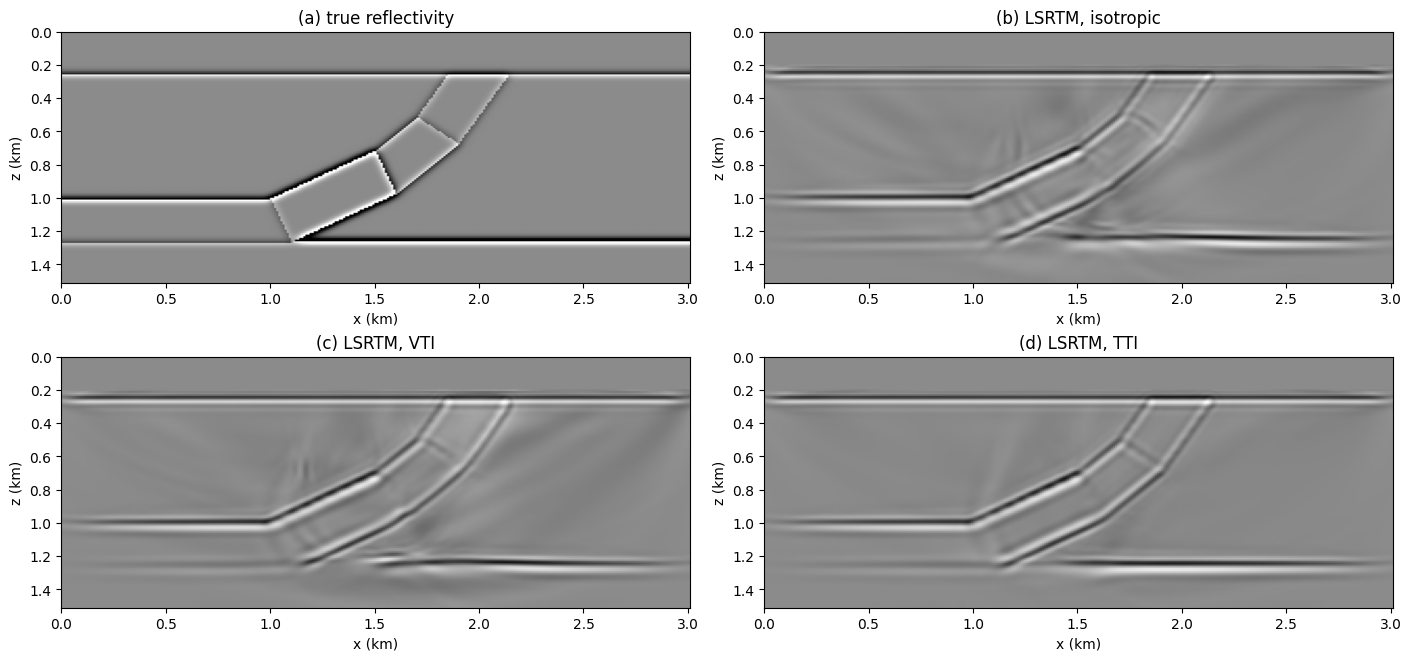

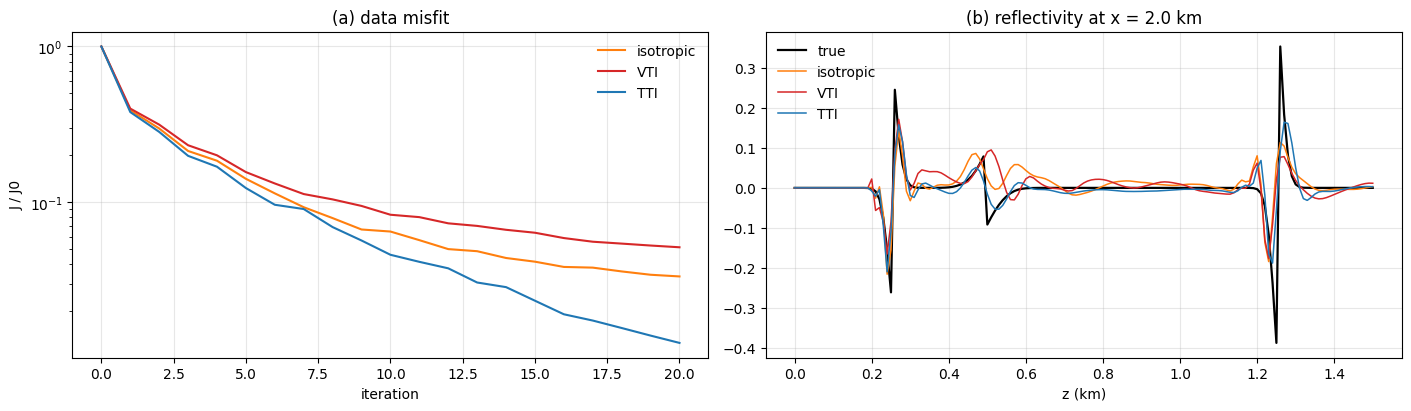

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 6.5), constrained_layout=True)
lo, hi = np.percentile(m_true, [1, 99])
for a, (f, title) in zip(ax.ravel(), [(m_true, "(a) true reflectivity")] +
                         [(results[c][0], f"({l}) LSRTM, {c}") for c, l in zip(CASES, "bcd")]):
    a.imshow(f, cmap="gray", vmin=lo, vmax=hi, extent=extent, aspect="auto")
    a.set_title(title); a.set_xlabel("x (km)"); a.set_ylabel("z (km)")
plt.show()

colors = {"isotropic": "tab:orange", "VTI": "tab:red", "TTI": "tab:blue"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for case, (m, hist) in results.items():
    ax[0].semilogy(hist / hist[0], color=colors[case], label=case)
ax[0].set_title("(a) data misfit"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("J / J0")
ax[0].legend(frameon=False); ax[0].grid(alpha=0.3)
ix = int(2000 / dh)                       # the trace at x = 2 km crosses the tilted bed
z = np.arange(nz) * dh / 1000
ax[1].plot(z, m_true[:, ix], "k", lw=1.6, label="true")
for case, (m, hist) in results.items():
    ax[1].plot(z, m[:, ix], color=colors[case], lw=1.1, label=case)
ax[1].set_title(f"(b) reflectivity at x = {ix * dh / 1000:.1f} km"); ax[1].set_xlabel("z (km)")
ax[1].legend(frameon=False); ax[1].grid(alpha=0.3)
plt.show()

- **TTI**, the operator that made the data, fits them best -- the misfit falls to about 1 % of
  its start in 20 iterations -- and images both sides of the tilted bed and the boundaries
  between its segments where they are.
- **VTI** ends with the largest misfit, above the isotropic run. The bed's symmetry axis is normal
  to the bed, so a wave reflected off it travels along that axis, at $v_p$; with the axis vertical
  instead, VTI sees the same wave travel at the bed's dip from its axis, at more than $v_p$
  ($\varepsilon, \delta > 0$), and the two sides of the bed come out displaced and blurred. The
  isotropic operator uses $v_p$ in every direction, which is right along the true axis.
- The trace at $x = 2$ km (b) crosses the 60-degree segment: between 0.3 and 0.6 km, where it runs
  through the bed, the TTI image follows the true reflectivity while the isotropic and VTI images
  oscillate around it.

## 5. Notes

- **`s_gradient`.** The Born pair takes the same `s_gradient` option as `AcousticVTI` /
  `AcousticTTI`; the default `'adjoint'` back-propagates the scattered adjoint with its own
  $S_n$. With `'frozen'` or `'exact'` the first iteration ($m_p = 0$, so a zero scattered field)
  back-propagates the residual with $S = 0$, an elliptical medium. See
  [Pure-qP VTI / TTI](../../user-guide/qp_born/).
- **Memory.** On `impl='c'` the pair runs with `memory=Full()` or `memory=BoundarySaving(...)`
  (gpu, cpu or disk storage; fp32, fp16 or bf16 -- int8 is refused), not with checkpointing,
  domain decomposition or a free surface. The boundary-saving shell covers the whole CPML frame
  of both fields, so it grows with `abcn` and with the batch: four shots, `abcn = 20` and 1601
  steps take about 6.5 GB here.

## References

1. Liang, K., Cao, D., Sun, S., & Yin, X. (2023). Decoupled wave equation and forward modeling of qP wave in VTI media with the new acoustic approximation. *Geophysics, 88*(1), WA335–WA344. [doi:10.1190/geo2022-0292.1](https://doi.org/10.1190/geo2022-0292.1) — the pure-qP VTI / TTI equations (space-domain $S_n$) whose Born pair this notebook images with.
2. Mu, X., Huang, J., Yang, J., Guo, X., & Guo, Y. (2020). Least-squares reverse time migration in TTI media using a pure qP-wave equation. *Geophysics, 85*(4), S199–S216. [doi:10.1190/geo2019-0320.1](https://doi.org/10.1190/geo2019-0320.1) — LSRTM in TTI media with a pure qP-wave equation; the tilted-bed model here follows the style of their synthetic tests.